# Machine Learning Model for Loan Approval

## Overview
FinTech Innovations partners with traditional banks to modernize their loan approval process. Today, loan officers review applications by hand, which leads to inconsistent decisions and slow responses.

This project builds a machine learning model on 20,000 past loan applications to predict whether a loan should be approved. The goal is a faster, more consistent, and more explainable decision-support tool, following the CRISP-DM framework.


# PART 1: BUSINESS UNDERSTANDING AND PLANNING PHASE
 
## Business Understanding

**Current process and its limits:**

Loan officers review applications by hand. That makes decisions inconsistent (two officers can judge the same applicant differently), slow, and open to personal bias. Creditworthy people can get overlooked just because they don’t fit traditional criteria.

**Stakeholders and what they need**

- Loan officers want faster, clearer decision support.
- Risk and finance teams want fewer defaults and lower losses.
- Applicants want fair, quick decisions.
- Regulators want decisions that are explainable and unbiased.
- Partner banks want profit without extra risk.

**What model errors cost**

- Approving a bad loan (a missed default) costs about $50,000.
- Denying a good loan costs about $8,000 in lost profit.

A bad approval is about 6x more costly than a missed good loan, so the model should be judged mainly on business cost, not raw accuracy.

**Classification or regression?**
We use **classification**, predicting `LoanApproved` (1 = approved, 0 = denied). The business decision is yes/no, and the costs attach to specific mistakes. The model's predicted probabilities can still act as a risk score for loan officers.

**Metrics**

| Metric | Why we use it |
|---|---|
| Precision (approved class) | Of the applicants we approve, how many were truly good? Protects against approving bad loans. |
| Recall (approved class) | Of the truly good applicants, how many did we approve? Protects against missing good loans. |
| ROC-AUC | How well the model separates good from bad applicants, regardless of cutoff. |
| Custom cost metric | Total dollars lost: $50,000 × bad loans approved + $8,000 × good loans denied. Lower is better. |

**Baselines to beat**

| Baseline | Calculation | Total cost |
|---|---|---|
| Approve everyone | 15,220 × $50,000 | $761,000,000 |
| Deny everyone | 4,780 × $8,000 | $38,240,000 |

A useful model should cost less than $38.2M while still approving a meaningful number of applicants. A plain logistic regression is our model baseline.

**Success criteria**

- Total cost must be lower than the "deny everyone" baseline.
- Recall must be high enough that the model approves most good applicants, not just denies everyone.
- ROC-AUC must be well above 0.5, so the model ranks applicants better than chance.
- The model must be easy to explain to regulators.

**Note on baselines:** the $761M and $38.2M figures are for all 20,000 applications. The test set has 4,000 applications, so its baselines are about $152M (approve everyone) and $7.65M (deny everyone).

**Limitation to consider**
`LoanApproved` is a past human decision, not actual repayment, so the model learns to copy those decisions, including any bias in them. We treat "approved" as a stand-in for "good loan".



# PART 2: DATA UNDERSTANDING & EXPLORATION PHASE

## Data Understanding

**Basic data characteristics**
- 20,000 applications and 35 columns: 18 integer, 10 float, and 7 text.
- The target LoanApproved is binary: 15,220 denied (76.1%) and 4,780 approved (23.9%), so the classes are imbalanced. A model that denies everyone would score 76% accuracy, so accuracy alone is misleading.
- RiskScore is continuous and will not be used as a predictor (see leakage below).

**Distributions**
- Right-skewed with long tails: LoanAmount (mean ~24.9k, median ~21.9k, max ~184k), MonthlyIncome, TotalAssets, TotalLiabilities, NetWorth, SavingsAccountBalance.
- Roughly symmetric: CreditScore (343 to 712) and Age (18 to 80).

**Relationships between features**
- Strongest with approval: `MonthlyIncome` (+0.60) and `TotalDebtToIncomeRatio` (-0.41). `LoanAmount` (-0.24) is next.
- Leakage: `RiskScore` (-0.77) is excluded as likely an output of the decision process.
- Redundant pairs:`NetWorth` and `TotalAssets` (0.98), `InterestRate` and `BaseInterestRate` (0.83). One of each pair will be dropped for the linear model.
- Credit score:`CreditScore` relates strongly to the interest rates (-0.60 and -0.72) but only weakly to approval (+0.14). Past decisions seem to lean more on income and debt burden than on credit history.
- Categorical features: approval varies most by employment status (unemployed about 18%, employed about 24%, self-employed about 28%). Other categories sit close to the overall 23.9% rate.

**Feature Types**

| Type | Features |
|---|---|
| Numeric | All integer and float columns (for example MonthlyIncome, LoanAmount, CreditScore)|
| Categorical | `EmploymentStatus`, `MaritalStatus`, `HomeOwnershipStatus`, `LoanPurpose`, `BankruptcyHistory` |
| Ordinal | `EducationLevel` (High School < Associate < Bachelor < Master < Doctorate) |
| Binary flag | `PreviousLoanDefaults` (0/1), EducationMissing (0/1, whether education was blank). |

**Other features:** the remaining numeric features were checked with summary statistics and show no unusual shapes beyond the outliers noted above.

**Feature engineering opportunities**

- **`EducationMissing` flag (created):** every applicant with a blank education level was denied, so a 0/1 flag keeps that pattern.

To keep the project simple, we created only the `EducationMissing` flag. The other ideas are listed under potential improvements.

In [30]:
# Imports
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier 

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

pd.set_option("display.max_columns", None)

In [31]:
# EDA Code Here - Create New Cells As Needed
df = pd.read_csv('financial_loan_data.csv')
df.head()

,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,Own,183,0.354418,1,2,0.358336,No,Home,0,29,9,7632.0,1202,146111,19183,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,Mortgage,496,0.087827,5,3,0.330274,No,Debt Consolidation,0,21,9,4627.0,3460,53204,9595,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,Rent,902,0.137414,2,0,0.244729,No,Education,0,20,22,886.0,895,25176,128874,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,Mortgage,755,0.267587,2,1,0.436244,No,Home,0,27,10,1675.0,1217,104822,5370,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,Mortgage,274,0.320535,0,0,0.078884,No,Debt Consolidation,0,26,27,1555.0,4981,244305,17286,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0


In [32]:
print("Dataset shape:", df.shape)

df.info()

print(df.describe())

print(df.isnull().sum())

Dataset shape: (20000, 35)
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  str    
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  str    
 4   EducationLevel              19099 non-null  str    
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  str    
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  str    
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfOpenCre

In [33]:
df['LoanApproved'].value_counts()

LoanApproved
0    15220
1     4780
Name: count, dtype: int64

LoanApproved
0    15220
1     4780
Name: count, dtype: int64
LoanApproved
0    76.1
1    23.9
Name: proportion, dtype: float64


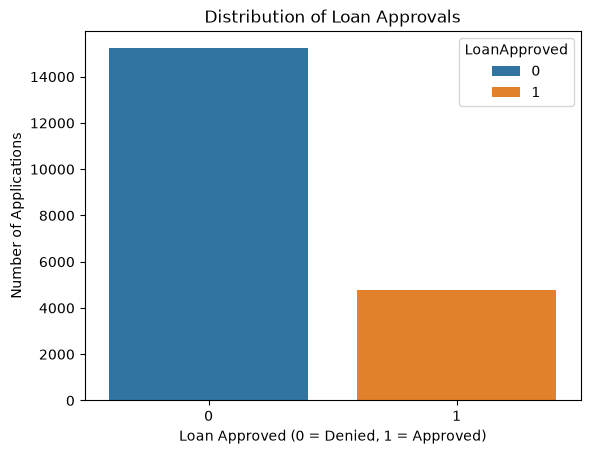

In [34]:
print(df["LoanApproved"].value_counts())
print(df["LoanApproved"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="LoanApproved", hue="LoanApproved")
plt.title("Distribution of Loan Approvals")
plt.xlabel("Loan Approved (0 = Denied, 1 = Approved)")
plt.ylabel("Number of Applications")
plt.show()

In [35]:
# 1. Quick look: correlation with the target
print(df.corr(numeric_only=True)["LoanApproved"].sort_values())

RiskScore                    -0.766137
TotalDebtToIncomeRatio       -0.410399
InterestRate                 -0.301646
BaseInterestRate             -0.247263
LoanAmount                   -0.239496
MonthlyLoanPayment           -0.184272
LoanDuration                 -0.094558
MonthlyDebtPayments          -0.070415
PreviousLoanDefaults         -0.065343
TotalLiabilities             -0.029434
CreditCardUtilizationRate    -0.010466
NumberOfCreditInquiries      -0.005885
NumberOfOpenCreditLines      -0.004769
SavingsAccountBalance        -0.000258
DebtToIncomeRatio             0.000034
CheckingAccountBalance        0.000660
NumberOfDependents            0.001717
UtilityBillsPaymentHistory    0.003303
JobTenure                     0.004997
PaymentHistory                0.030804
LengthOfCreditHistory         0.105949
Experience                    0.140755
Age                           0.141029
CreditScore                   0.142000
TotalAssets                   0.184011
NetWorth                 

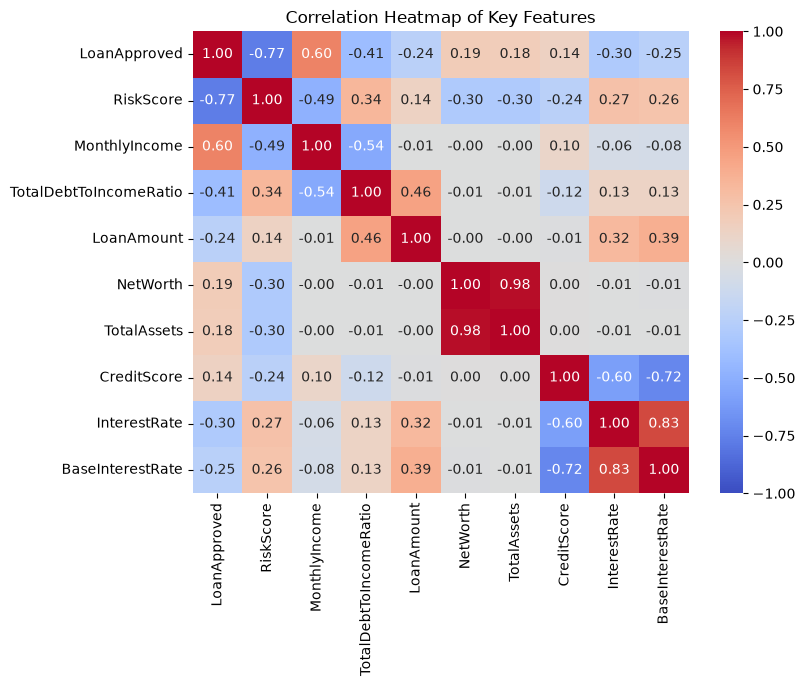

In [36]:
cols = ["LoanApproved", "RiskScore", "MonthlyIncome", "TotalDebtToIncomeRatio",
        "LoanAmount", "NetWorth", "TotalAssets", "CreditScore",
        "InterestRate", "BaseInterestRate"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Key Features")
plt.show()

In [37]:
print(df[["RiskScore", "InterestRate", "BaseInterestRate", "MonthlyLoanPayment"]].corr())

                    RiskScore  InterestRate  BaseInterestRate  \
RiskScore            1.000000      0.268203          0.256233   
InterestRate         0.268203      1.000000          0.834557   
BaseInterestRate     0.256233      0.834557          1.000000   
MonthlyLoanPayment   0.115501      0.127497          0.118030   

                    MonthlyLoanPayment  
RiskScore                     0.115501  
InterestRate                  0.127497  
BaseInterestRate              0.118030  
MonthlyLoanPayment            1.000000  


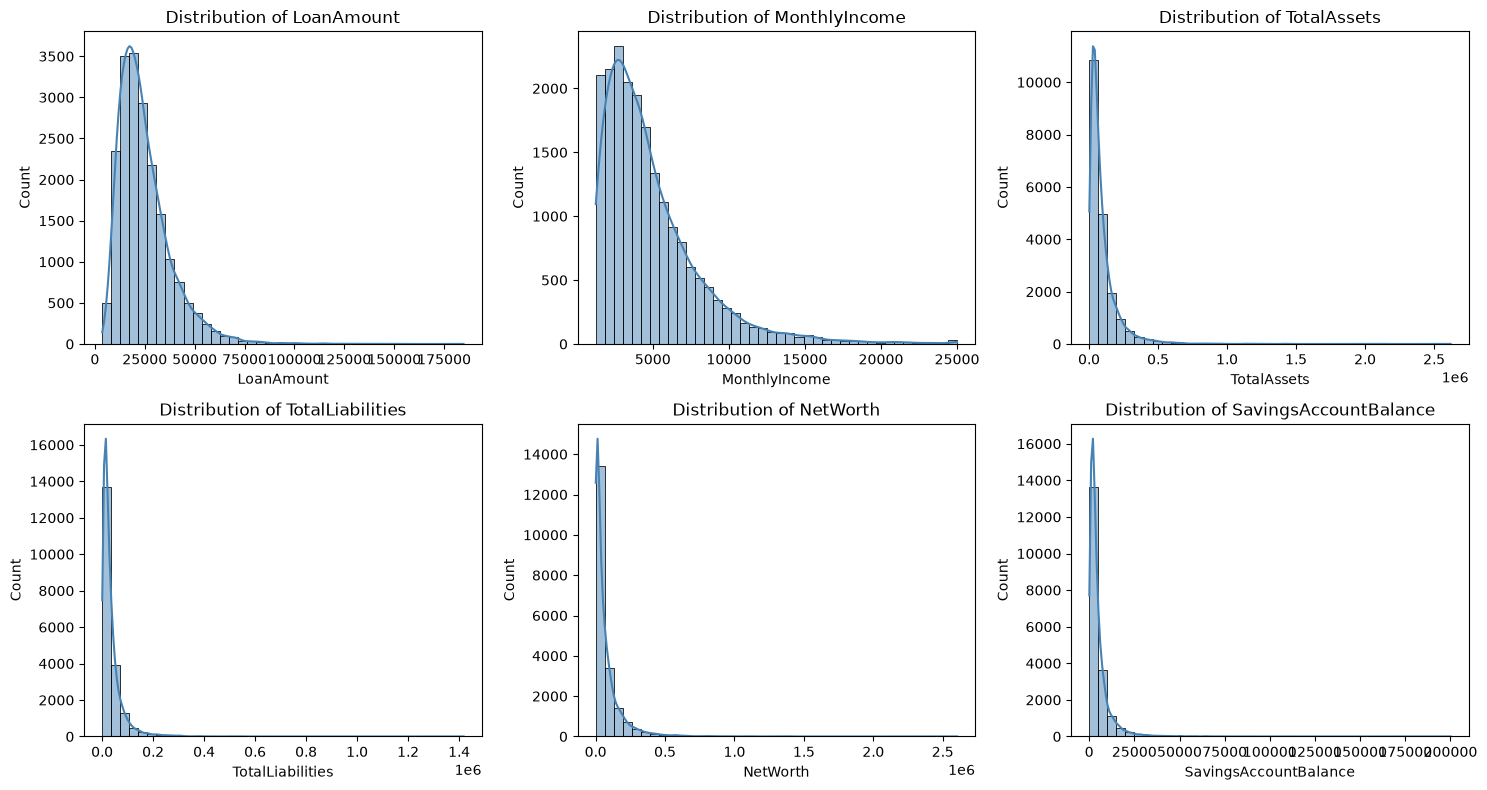

In [38]:
skewed_cols = ["LoanAmount", "MonthlyIncome", "TotalAssets",
               "TotalLiabilities", "NetWorth", "SavingsAccountBalance"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, skewed_cols):
    sns.histplot(df[col].dropna(), bins=40, kde=True, color="steelblue", ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [39]:
cat_cols = ["EmploymentStatus", "MaritalStatus", "HomeOwnershipStatus",
            "LoanPurpose", "BankruptcyHistory", "EducationLevel"]

for col in cat_cols:
    print(df.groupby(col)["LoanApproved"].mean().sort_values())
    print()

EmploymentStatus
Unemployed       0.181884
Employed         0.240021
Self-Employed    0.278449
Name: LoanApproved, dtype: float64

MaritalStatus
Widowed     0.230108
Married     0.237033
Single      0.239541
Divorced    0.244822
Name: LoanApproved, dtype: float64

HomeOwnershipStatus
Other       0.204813
Rent        0.227698
Own         0.248857
Mortgage    0.251543
Name: LoanApproved, dtype: float64

LoanPurpose
Other                 0.223330
Debt Consolidation    0.235130
Home                  0.237975
Auto                  0.242687
Education             0.252992
Name: LoanApproved, dtype: float64

BankruptcyHistory
Yes    0.110687
No     0.246095
Name: LoanApproved, dtype: float64

EducationLevel
High School    0.152539
Associate      0.214026
Bachelor       0.277912
Master         0.364814
Doctorate      0.456522
Name: LoanApproved, dtype: float64



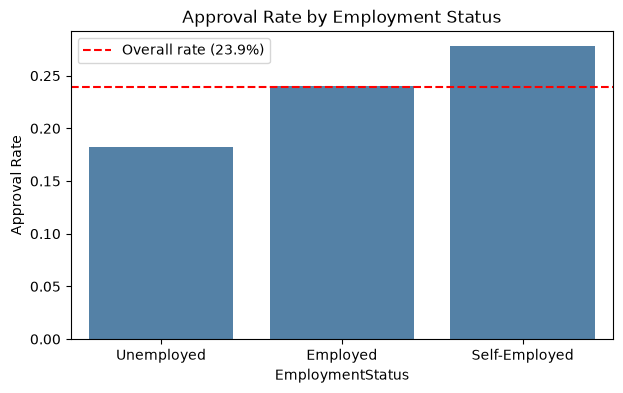

In [40]:
rates = df.groupby("EmploymentStatus")["LoanApproved"].mean().sort_values()

plt.figure(figsize=(7, 4))
sns.barplot(x=rates.index, y=rates.values, color="steelblue")
plt.axhline(df["LoanApproved"].mean(), color="red", linestyle="--", label="Overall rate (23.9%)")
plt.title("Approval Rate by Employment Status")
plt.ylabel("Approval Rate")
plt.legend()
plt.show()

In [41]:
print(df["EducationLevel"].unique())

<StringArray>
['Master', 'Associate', 'Bachelor', 'High School', nan, 'Doctorate']
Length: 6, dtype: str


**Data Quality Issues and Implications**

| Issue | Implication |
|---|---|
| `AnnualIncome` stored as text (for example `$39,948.00`) | Strip `$` and commas, then convert to numeric. Drop Annual Income as it is the same as Monthly Income |
| Missing: `EducationLevel` (901), `MaritalStatus` (1,331), `SavingsAccountBalance` (572) | Impute inside the pipeline to avoid leakage. all 901 blank EducationLevel rows were denied, so we fill in the pipeline and add the EducationMissing flag. |
| Extreme values in `LoanAmount`, savings, `TotalDebtToIncomeRatio` | Can distort logistic regression, so scale numeric features; trees are robust |
| `RiskScore` is leakage | Exclude it |
| Redundant correlated features | Drop one of each pair for logistic regression to keep coefficients interpretable |
| Target is a past human decision, not actual repayment | The model may copy past bias; note as a limitation 



# PART 3: PIPELINE DEVELOPMENT PHASE

## Data Preparation


In [42]:
df['AnnualIncome'] = df['AnnualIncome'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

In [43]:
print(df["AnnualIncome"].dtype)
print(df["AnnualIncome"].describe())

float64
count     20000.000000
mean      59161.473550
std       40350.845168
min       15000.000000
25%       31679.000000
50%       48566.000000
75%       74391.000000
max      485341.000000
Name: AnnualIncome, dtype: float64


In [44]:
print(df[["AnnualIncome", "MonthlyIncome"]].corr())

               AnnualIncome  MonthlyIncome
AnnualIncome       1.000000       0.989911
MonthlyIncome      0.989911       1.000000


In [45]:
missing_cols = ["EducationLevel", "MaritalStatus", "SavingsAccountBalance"]

for col in missing_cols:
    n = df[col].isnull().sum()
    rate_missing = df.loc[df[col].isnull(), "LoanApproved"].mean()
    rate_present = df.loc[df[col].notnull(), "LoanApproved"].mean()
    print(f"{col}: {n} missing ({n / len(df):.1%})")
    print(f"  approval rate if missing: {rate_missing:.3f}  | if present: {rate_present:.3f}\n")

EducationLevel: 901 missing (4.5%)
  approval rate if missing: 0.000  | if present: 0.250

MaritalStatus: 1331 missing (6.7%)
  approval rate if missing: 0.245  | if present: 0.239

SavingsAccountBalance: 572 missing (2.9%)
  approval rate if missing: 0.264  | if present: 0.238



**Pipeline setup**

Steps that don't learn anything from the data happen first: adding the `EducationMissing` flag, dropping redundant and leakage columns, and separating features (`X`) from the target (`y`). We then split into train and test sets. Everything that learns from the data (filling blanks, scaling, encoding) goes inside the pipeline and is fitted on the training rows only, so nothing leaks from the test set.

In [46]:
df["EducationMissing"] = df["EducationLevel"].isnull().astype(int)

In [47]:
df_clean = df.drop(columns=["AnnualIncome", "RiskScore", "TotalAssets", "BaseInterestRate"])

X = df_clean.drop(columns=["LoanApproved"])
y = df_clean["LoanApproved"]

print(X.shape, y.shape)

(20000, 31) (20000,)


In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (16000, 31)
Testing features: (4000, 31)

Training target distribution:
LoanApproved
0    0.761
1    0.239
Name: proportion, dtype: float64

Testing target distribution:
LoanApproved
0    0.761
1    0.239
Name: proportion, dtype: float64


In [49]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str", "category", "bool"]
).columns.tolist() 

categorical_features.remove("EducationLevel")

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age', 'CreditScore', 'Experience', 'LoanAmount', 'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory', 'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory', 'JobTenure', 'NetWorth', 'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'EducationMissing']

Categorical features:
['EmploymentStatus', 'MaritalStatus', 'HomeOwnershipStatus', 'BankruptcyHistory', 'LoanPurpose']


In [50]:
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [51]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [52]:
from sklearn.preprocessing import OrdinalEncoder
education_order = [["High School", "Associate", "Bachelor", "Master", "Doctorate"]]

education_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=education_order))
    ]
)

In [53]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        ),
        (
            "education",
            education_pipeline,
            ["EducationLevel"]
        )
    ]
)

In [54]:
# testing that preprocessing is working

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print(X_train_ready.shape)
print(X_test_ready.shape)

(16000, 44)
(4000, 44)


**Preprocessing reasoning**

- **Numeric (25 columns):** median fill (robust to the skewed, extreme values) and standard scaling (needed so large-scale columns don't dominate logistic regression).
- **Categorical (5 columns):** most-frequent fill and one-hot encoding, because the labels have no natural order. `handle_unknown="ignore"` stops errors on unseen categories.
- **Ordinal (`EducationLevel`):** most-frequent fill and ordinal encoding with an explicit order (High School < Associate < Bachelor < Master < Doctorate). The `EducationMissing` flag keeps the finding that every blank was denied.
- Everything that learns from the data sits inside the pipeline and is fitted on training rows only, so nothing leaks from the test set.

# PART 4: MODELING

**Custom cost metric**

Accuracy ignores the fact that errors have different prices. This metric charges $50,000 for each bad loan approved (false positive) and $8,000 for each good loan denied (false negative). Lower is better. `make_scorer` wraps it so `GridSearchCV` can use it, with `greater_is_better=False` because sklearn always maximizes. 

### Modeling approach

**Algorithms:** Logistic Regression is the interpretable baseline, because regulators need explainable decisions. Random Forest is a more flexible challenger. Both use the same preprocessor, so the comparison is fair.

**Validation:** the data was split 80/20, keeping the same denied/approved mix in both parts. All tuning used 5-fold cross-validation on the training set only. The test set was held back for the final report.

**Metrics:** each setting was scored on cost, precision, recall, and ROC-AUC. The winner was chosen on cost, because it reflects the real price of each mistake.

In [56]:
def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return 50000 * fp + 8000 * fn

cost_scorer = make_scorer(total_cost, greater_is_better=False)

print(total_cost(y_test, np.ones(len(y_test))))    # approve everyone
print(total_cost(y_test, np.zeros(len(y_test))))   # deny everyone

152200000
7648000


In [57]:
# Models and Pipelines
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    )
}

In [58]:
pipelines = {}

for model_name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipelines[model_name] = pipeline

print("Created pipelines:")
for name in pipelines:
    print(name)

Created pipelines:
Logistic Regression
Random Forest


In [59]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 5],
        "model__class_weight": [None, "balanced"]
    }
}

In [60]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "cost": cost_scorer,
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

In [62]:
# grid search 

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "cost": cost_scorer,          # CHANGE 1: our business metric added
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

grid_searches = {}
selection_results = []

for model_name, pipeline in pipelines.items():

    print(f"\nTraining and tuning: {model_name}")

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring=scoring,
        refit="cost",             # CHANGE 2: pick the winner by cost, not F1
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    grid_searches[model_name] = grid_search

    best_index = grid_search.best_index_

    selection_results.append({
        "Model": model_name,
        "Best CV Cost": -grid_search.best_score_,   # CHANGE 3: flip the sign back to dollars
        "Best CV F1": grid_search.cv_results_[
            "mean_test_f1"
        ][best_index],                              # CHANGE 4: F1 now read from the results table
        "Best CV Precision": grid_search.cv_results_[
            "mean_test_precision"
        ][best_index],
        "Best CV Recall": grid_search.cv_results_[
            "mean_test_recall"
        ][best_index],
        "Best CV ROC-AUC": grid_search.cv_results_[
            "mean_test_roc_auc"
        ][best_index],
        "Best Parameters": grid_search.best_params_
    })

    print("Best parameters:", grid_search.best_params_)
    print("Best cross-validation cost:", round(-grid_search.best_score_))


Training and tuning: Logistic Regression
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'model__C': 1, 'model__class_weight': None}
Best cross-validation cost: 2949200

Training and tuning: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best cross-validation cost: 4781200


### Tuning

`GridSearchCV` tried every combination of settings.

- **Logistic Regression (6 combinations):** regularization strength `C` (0.1, 1, 10) and `class_weight` (none or balanced).
- **Random Forest (24 combinations):** number of trees (100, 200), tree depth (none, 10, 20), minimum rows per leaf (1, 5), and `class_weight` (none or balanced).

Each combination was tested with 5-fold cross-validation, so the search ran 30 fits for Logistic Regression and 120 for Random Forest.

In [63]:
selection_df = pd.DataFrame(selection_results)

selection_df = selection_df.sort_values(
    by="Best CV Cost",
    ascending=True
).reset_index(drop=True)

selection_df

,Model,Best CV Cost,Best CV F1,Best CV Precision,Best CV Recall,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,2949200.0,0.929549,0.934215,0.924943,0.995071,"{'model__C': 1, 'model__class_weight': None}"
1,Random Forest,4781200.0,0.839199,0.896504,0.788956,0.978727,"{'model__class_weight': None, 'model__max_dept..."


- Logistic regression’s recall is 0.92. It is approving most of the truly approved applicants, not just denying everyone to keep costs low.
- However, ROC-AUC is very high based on loan data.

In [64]:
# score both models on test set
test_results = []
best_models = {}

for model_name, grid_search in grid_searches.items():

    best_model = grid_search.best_estimator_
    best_models[model_name] = best_model

    y_pred = best_model.predict(X_test)

    y_probability = best_model.predict_proba(X_test)[:, 1]

    cost = total_cost(y_test, y_pred)    # ADDED: our business metric

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_probability)

    test_results.append({
        "Model": model_name,
        "Cost": cost,                    # ADDED
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by="Cost",                           # CHANGED: lowest cost first
    ascending=True
).reset_index(drop=True)

test_results_df.round(3)

,Model,Cost,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,3594000,0.968,0.936,0.929,0.932,0.995
1,Random Forest,5296000,0.934,0.910,0.804,0.854,0.980


- The result holds up on unseen data. Logistic regression’s test cost of $3.59M is about 53% lower than the deny-everyone baseline
- The ranking didn’t change. Logistic regression still wins on every metric
- Accuracy is 0.968 for logistic regression

# PART 5: EVALUATION AND CONCLUSION

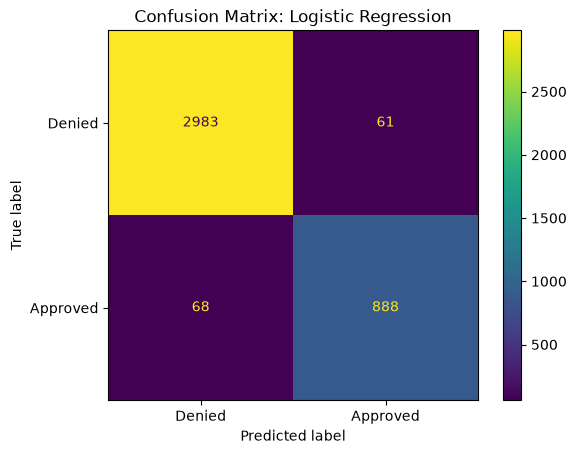

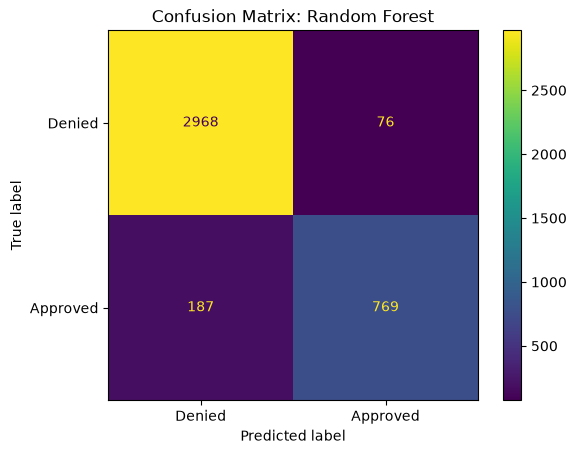

In [65]:
for model_name, best_model in best_models.items():

    y_pred = best_model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Denied", "Approved"]
    )

    display.plot()
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

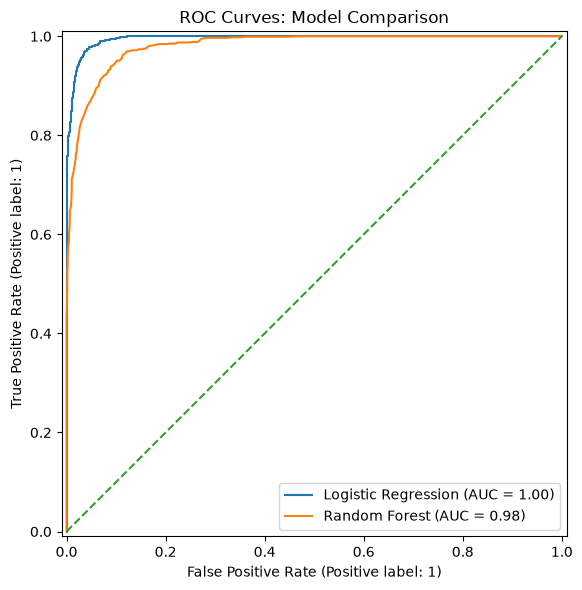

In [66]:
fig, ax = plt.subplots(figsize=(9, 6))

for model_name, best_model in best_models.items():

    RocCurveDisplay.from_estimator(
        best_model,
        X_test,
        y_test,
        ax=ax,
        name=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

plt.title("ROC Curves: Model Comparison")
plt.tight_layout()
plt.show()

- Logistic regression (blue) shoots straight up the left and is closest to the top-left corner. That means it catches almost all truly approved applicants while wrongly approving very few denied ones.
- On the other hand, Random forest (orange) sits below it the whole way, with a visibly lower curve.

In [67]:
final_model = best_models["Logistic Regression"]

feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = final_model.named_steps["model"].coef_[0]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance_df["Abs Coefficient"] = importance_df["Coefficient"].abs()

importance_df = importance_df.sort_values(
    by="Abs Coefficient",
    ascending=False
).reset_index(drop=True)

importance_df.head(10)

,Feature,Coefficient,Abs Coefficient
0,numerical__TotalDebtToIncomeRatio,-7.921680,7.921680
1,numerical__InterestRate,-5.145292,5.145292
2,numerical__MonthlyIncome,4.906653,4.906653
3,categorical__BankruptcyHistory_No,3.137279,3.137279
4,categorical__BankruptcyHistory_Yes,-3.110071,3.110071
5,numerical__NetWorth,2.834646,2.834646
6,numerical__CreditScore,-2.420191,2.420191
7,categorical__EmploymentStatus_Unemployed,-2.019302,2.019302
8,numerical__LoanAmount,-1.955804,1.955804
9,numerical__LengthOfCreditHistory,1.668531,1.668531


**Feature importance (logistic regression coefficients)** 

The strongest drivers of approval are financial: - `TotalDebtToIncomeRatio` (higher debt burden lowers approval odds the most), `InterestRate` (higher lowers), - `MonthlyIncome` (higher raises), `BankruptcyHistory` (a past bankruptcy lowers), and `NetWorth` (higher raises). Unemployed status, larger loan amounts, and a short credit history also lower approval. Age and marital status are not among the top drivers.

**Caveats:** `CreditScore` shows a negative coefficient even though its raw correlation with approval is positive. This is likely due to its overlap with `InterestRate` (correlation -0.60), so it should not be read as "higher credit scores hurt approval". `InterestRate` ranks second, but it may be set after approval, so the model should be re-tested without it.

**Business recommendations**
- Focus review effort on applicants with high debt-to-income ratios, since this is the single strongest signal.
- Confirm with the bank whether the interest rate is known at application time.
- Record education level consistently, because every blank was denied in the past data.
- Review the effect of past bankruptcy for consistency and fairness.

In [68]:
y_pred = final_model.predict(X_test)

segment_results = []

for segment in X_test["EmploymentStatus"].unique():

    mask = (X_test["EmploymentStatus"] == segment).values

    segment_results.append({
        "Segment": segment,
        "Applicants": mask.sum(),
        "Recall": recall_score(y_test[mask], y_pred[mask]),
        "Precision": precision_score(y_test[mask], y_pred[mask]),
        "Cost per applicant": total_cost(y_test[mask], y_pred[mask]) / mask.sum()
    })

pd.DataFrame(segment_results).round(3)

,Segment,Applicants,Recall,Precision,Cost per applicant
0,Employed,3402,0.928,0.942,829.512
1,Unemployed,287,0.860,0.896,1066.202
2,Self-Employed,311,0.976,0.899,1498.392


### Performance across segments (employment status)

| Segment | Applicants | Recall | Precision | Cost per applicant |
|---|---|---|---|---|
| Employed | 3,402 | 0.928 | 0.942 | $830 |
| Unemployed | 287 | 0.860 | 0.896 | $1,066 |
| Self-Employed | 311 | 0.976 | 0.899 | $1,498 |

The model performs best for employed applicants. For unemployed applicants recall is lowest (0.86), so good applicants in this group are more likely to be wrongly denied, which is a fairness concern. Self-employed applicants have the highest cost per applicant because a few wrong approvals ($50,000 each) add up in a small group. The unemployed and self-employed groups contain only about 300 applicants each, so these gaps are suggestive and should be confirmed on more data before acting on them.

In [69]:
print(pd.crosstab(X_test["EmploymentStatus"], y_test))

LoanApproved         0    1
EmploymentStatus           
Employed          2578  824
Self-Employed      229   82
Unemployed         237   50


In [70]:
lr_results = pd.DataFrame(grid_searches["Logistic Regression"].cv_results_)

lr_summary = lr_results[[
    "param_model__C",
    "param_model__class_weight",
    "mean_test_cost",
    "mean_test_recall",
    "mean_test_roc_auc"
]].copy()

lr_summary["mean_test_cost"] = -lr_summary["mean_test_cost"]

lr_summary = lr_summary.sort_values("mean_test_cost").reset_index(drop=True)
lr_summary.round(3)

,param_model__C,param_model__class_weight,mean_test_cost,mean_test_recall,mean_test_roc_auc
0,1.0,NaN,2949200.0,0.925,0.995
1,0.1,NaN,3019600.0,0.913,0.995
2,10.0,NaN,3037600.0,0.925,0.995
3,10.0,balanced,5312400.0,0.970,0.995
4,1.0,balanced,5612400.0,0.970,0.995
5,0.1,balanced,6378800.0,0.976,0.995


### Impact of parameter combinations (Logistic Regression)

- **`class_weight` had the biggest effect.** `"balanced"` makes the model approve more applicants, so recall rises (about 0.97 vs 0.92). But each wrong approval costs $50,000, so cost rose from about $2.95M to between $5.3M and $6.4M.
- **`C` had a small effect.** Without class weighting, cost ranged only from $2.95M to $3.04M, and `C = 1` was best.
- **ROC-AUC was 0.995 for every combination.** The settings changed where decisions are cut off, not how well applicants are ranked.
- The worst combination costs more than denying everyone, which shows why we judge models on cost and not on recall alone.

### Trade-offs and conclusion

Logistic Regression beat Random Forest on cost, precision, recall, and ROC-AUC, and it is easier to explain, so there was no trade-off between performance and interpretability. The forest chose the least restricted settings (no depth limit, one row per leaf), which suggests it overfits.

# PART 5: EVALUATION AND CONCLUSION

### Feature importance (logistic regression coefficients)

The strongest drivers of approval are financial:

- `TotalDebtToIncomeRatio`: higher debt burden lowers approval odds the most.
- `InterestRate`: a higher rate lowers approval odds.
- `MonthlyIncome`: higher income raises approval odds.
- `BankruptcyHistory`: a past bankruptcy lowers approval odds.
- `NetWorth`: higher net worth raises approval odds.

Unemployed status, larger loan amounts, and a short credit history also lower approval. Age and marital status are not among the top drivers.

## Limitations
- **The target is a past decision, not repayment.** The model learns to copy past approvals, including any bias in them.
- **Possible leakage.** `InterestRate` may be set after approval. We did not test the model without it.
- **Education blanks.** Every applicant with a blank education level was denied, which may reflect how the bank processed applications and not creditworthiness. 

## Recommendations for Implementation
- **Start as decision support.** Show loan officers the model's decision and approval probability, and keep a human in the loop.
- **Send borderline cases to a reviewer.** Applicants with middle-range probabilities should get a manual review.

## Potential Improvements
- **Test without `InterestRate`** to confirm the results do not depend on it.
